# 1. Mengambil Dataset

Total gambar ditemukan: 6594
Sample: /kaggle/input/datasets/fanconic/skin-cancer-malignant-vs-benign/data/train/malignant/404.jpg


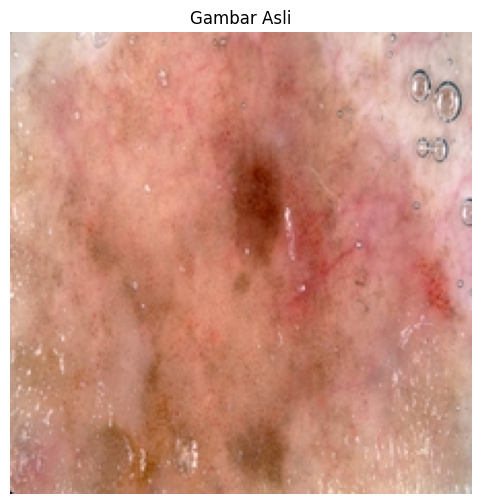

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter

# Ganti dengan path dataset kamu
INPUT_DIR = "/kaggle/input"

# Kumpulkan semua file gambar secara rekursif
ext = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
image_paths = []
for root, _, files in os.walk(INPUT_DIR):
    for f in files:
        if f.lower().endswith(ext):
            image_paths.append(os.path.join(root, f))

print(f"Total gambar ditemukan: {len(image_paths)}")

# Ambil satu gambar acak
sample_path = random.choice(image_paths)
print("Sample:", sample_path)

original = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(original)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

# 2. Gaussian Blur

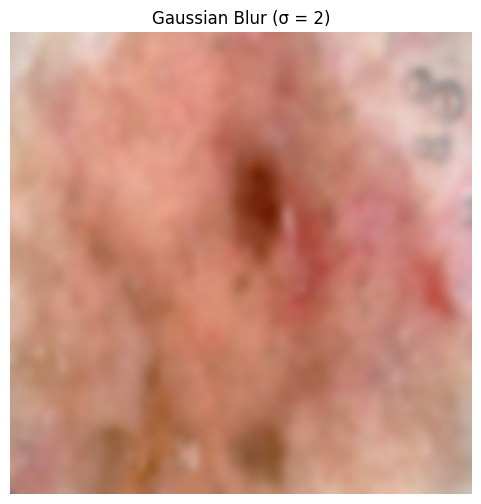

In [2]:
# Pada PIL, parameter radius pada GaussianBlur = standar deviasi (sigma)
gaussian_img = original.filter(ImageFilter.GaussianBlur(radius=2))

plt.figure(figsize=(6, 6))
plt.imshow(gaussian_img)
plt.title("Gaussian Blur (σ = 2)")
plt.axis("off")
plt.show()

# 3. Rotasi

Sudut rotasi: 81.83°


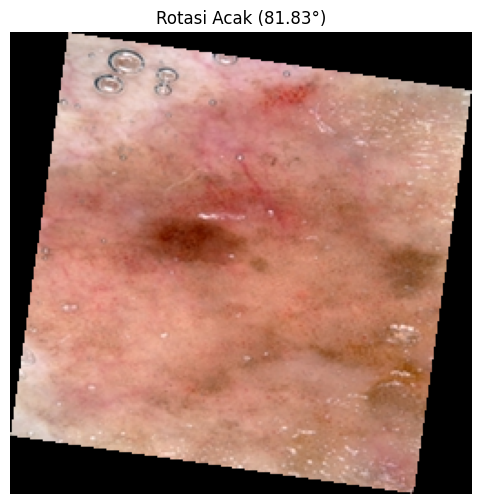

In [3]:
angle = random.uniform(-180, 180)
print(f"Sudut rotasi: {angle:.2f}°")

# expand=True agar gambar tidak terpotong
rotated_img = original.rotate(angle, resample=Image.BICUBIC, expand=True)

plt.figure(figsize=(6, 6))
plt.imshow(rotated_img)
plt.title(f"Rotasi Acak ({angle:.2f}°)")
plt.axis("off")
plt.show()

# 4. Sharpening

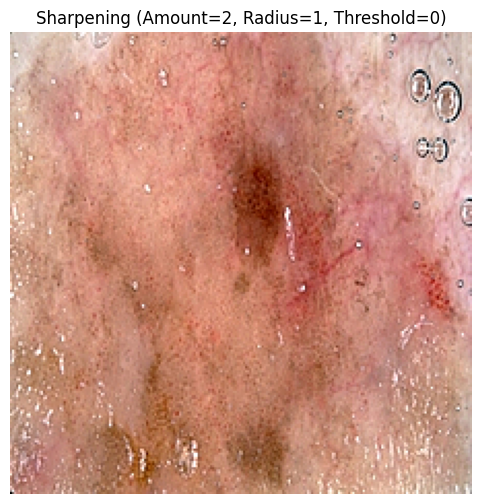

In [4]:
# UnsharpMask di PIL: percent = Amount dalam persen (Amount 2 = 200%)
sharpened_img = original.filter(
    ImageFilter.UnsharpMask(radius=1, percent=200, threshold=0)
)

plt.figure(figsize=(6, 6))
plt.imshow(sharpened_img)
plt.title("Sharpening (Amount=2, Radius=1, Threshold=0)")
plt.axis("off")
plt.show()

# 5. Perbandingan

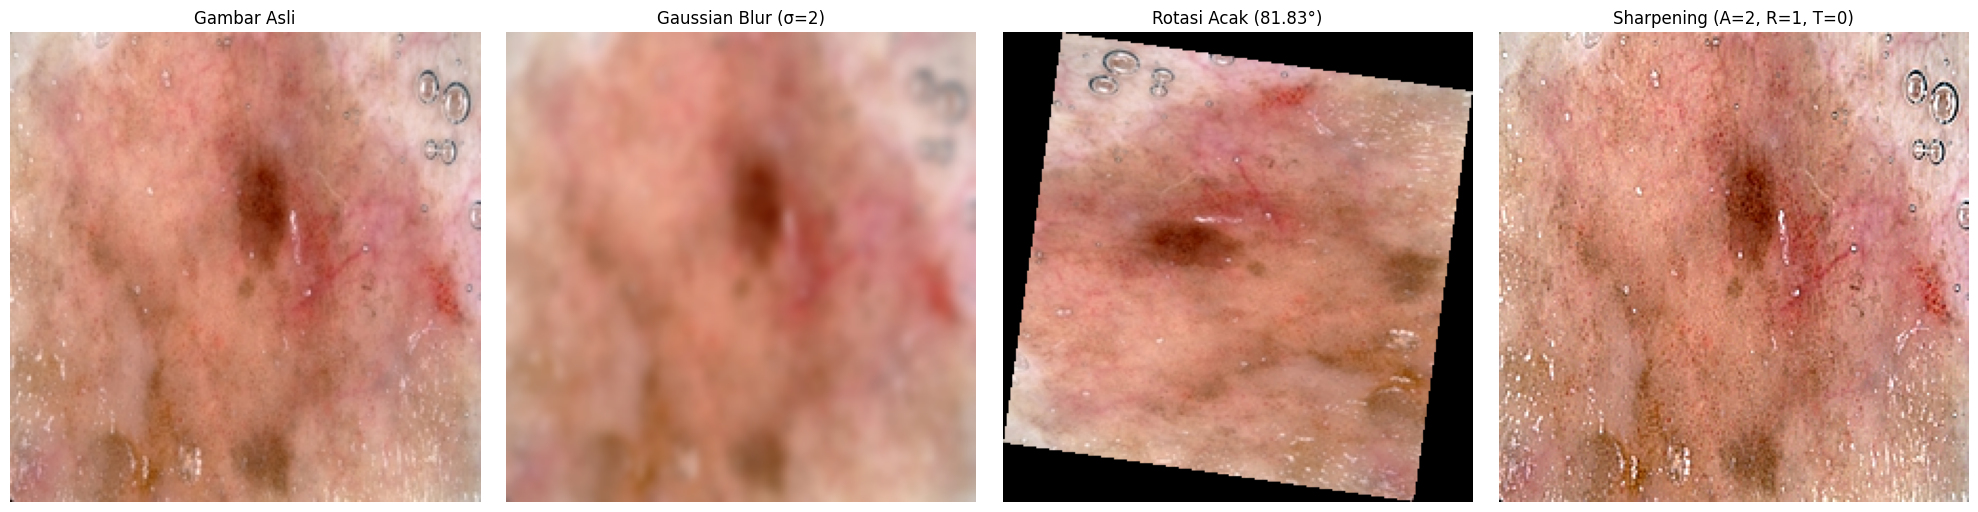

In [5]:
results = [
    ("Gambar Asli", original),
    ("Gaussian Blur (σ=2)", gaussian_img),
    (f"Rotasi Acak ({angle:.2f}°)", rotated_img),
    ("Sharpening (A=2, R=1, T=0)", sharpened_img),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (title, img) in zip(axes, results):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()